# Discrete Portfolio Optimization: QUBO and QAOA

## 1. Introduction

In the previous notebook we dealt with the classical Markowitz portfolio optimization problem, delving into the analytical solution, but also using numerical optimization methods. We extended this to a no-short-selling constraint. In this notebook we will extend this further by looking into discrete-asset-selling decisions. Instead of allowing continuous portfolio weights, we will start with an intial portfolio, K, consisting of equally weighted assets, and allow only discrete decisions.

The idea is to turn the optimization problem into a combinatorial optimization problem. We will express the problem mathematically and turn it into a Quadratic Unconstrained Binary Optimization (QUBO) problem and solve it exactly classically. Then we will map this onto a Ising Hamiltonian and try a Quantum Approximation Optimization Approach. If interested, I have a repository dedicated to Hamiltonian Simulation, where the first notebook deals with the Ising Hamiltonian, explaining the mathematics behind it in detail.

We want to compare classical and quantum approaches on something that is small and reproducible to see it works and its limitations. We start with the same problem:

$$ \min_{\pi \in \mathbb{R}^n} \frac{1}{2}\pi^T\Sigma\pi \qquad \textrm{s.t.} \qquad \pi^T m = m_p \quad \pi^T e=1$$

However, now we have the constraint: $ z_i = \begin{cases} 1\, \textrm{if asset i selected} \\ 0\, \textrm{otherwise}\end{cases}$. 
Inserting this into our equtions leads to:

$$ \frac{1}{K}m^Tz \quad \textrm{and}\quad\sigma^2 = \frac{1}{K^2}z^T\Sigma z $$

## 2. Mathematical Formulation

In this short section, I would like to take a step back and reformulate our optimization problem. This will become useful later. The idea is to introduce an alternative risk-return scalarization. We can motivate this through the Lagrangian multiplicators from notebook 1.

$$ \min_{\pi \in \mathbb{R}^n}\big[ \frac{1}{2}\pi^T\Sigma\pi - \lambda( \pi^Tm -m_p) -\mu(\pi^Te -1)\big]$$

We take the second condition into the minimum condition, so that condition is enforced. We introduce $\gamma = \frac{1}{\lambda}$. The parts containing $\lambda m_p$ and $\mu$ are constants and can therefore be taken out of the condition.

$$ \min_{\pi^Te=1}\big[ \frac{\gamma}{2}\pi^T\Sigma\pi - \pi^Tm\big]$$

Here, $\gamma$ is the risk-aversion parameter that controls the relative improtance of variance on expected return. For selected $\lambda$ we return to the classical Markowitz problem. This is now the cost function. We can formulate it using our binary variable.

$$ C(z) = \frac{\gamma}{2K^2}z^T\Sigma z - \frac{1}{K}m^Tz = \frac{\gamma}{2}\textrm{Var}(R^{\pi}) - \mathbb{E}[R^{\pi}] $$

For the benchmark, we will use the same values as in notebook 1.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from portfolio_optimization.discrete import discrete_portfolio_cost

In [2]:
n_assets = 4
m = np.array([0.04, 0.07, 0.10, 0.13])
e = np.ones(n_assets)
m_p = 0.08
Ap = np.array([[0.15, 0.02, 0.04, 0.01], 
            [0.02, 0.18, 0.03, 0.04],
            [0.04, 0.03, 0.22, 0.05],
            [0.01, 0.04, 0.05, 0.28]])

sigma = Ap.T @ Ap

# set K (initial portfolio weight) = 2
K=2
# random selction of yes no yes no (50% in asset 1 and 50% in asset 2)
z = np.array([1, 0, 1, 0])
# set risk-aversion parameter = 1
gamma= 1

Let us find a classical benchmark before going forward. Our problem is:
$$z^{\star} = \argmin_{\substack{z\in\{0,4\}^4 \\ \sum_i z_i=2}} C(z) $$
As we only have four assets in this trial, the number of possible portfolios is only 6. We will find the optimal portfolio via "brute force". This is simply done so that we have a benchmark for our QUBO and QAOA. For more assets this number skyrockets, so this is not a very efficient method whatsoever.

In [3]:
from itertools import combinations

In [4]:
# make a list of all possible portfolio combinations. Th distribution is binomial so we can use combinations
z_all = []

for selected in combinations(range(n_assets),K):
    z = np.zeros(n_assets,dtype= int)
    z[list(selected)]=1
    z_all.append(z)

# calculate the cost for ever portfolio configuration
costs = []

for z in z_all:
    cost = discrete_portfolio_cost(z, sigma, m, K, gamma)
    costs.append(cost)

# solve the optimization problem and print the solutions
min_index = np.argmin(costs)
zstar= z_all[min_index]
min_cost = np.min(costs)

print('The optimal portfolio is: ', zstar)
print('The minimum cost is: ', min_cost)


The optimal portfolio is:  [0 0 1 1]
The minimum cost is:  -0.09135


## 3. QUBO

Now that we have a benchmark for the global optimum of the constellation, we will formulate this as a Quadratic Unconstrained Binary Optimization problem and compare the results. We currently want to minimize:

$$ C(z) = \frac{\gamma}{2K^2}z^T\Sigma z - \frac{1}{K}m^Tz \qquad \textrm{s.t.} \qquad \sum_i z_i =K $$

To turn this into a QUBO, we will introduce a penalty A, with the constraint put explicitly into our equation. The idea is that every portfolio that is "not allowed", becomes too expensive to, and is therefore unfavourable. We can write this as:

$$ C_{\textrm{QUBO}}(z) = C(z) + A\big(\sum_iz_i -K\big)^ 2=  \frac{\gamma}{2K^2}z^T\Sigma z - \frac{1}{K}m^Tz +A\big(\sum_iz_i -K\big)^2 $$

We need to expand the terms in the bracket, to get to a more familiar expression.

$$ A\big(\sum_iz_i -K\big)^2 = A \big(\sum_iz_i\big)^2 -2A\sum_iz_iK +AK^2 =A\big(\sum_iz_i^2 +\sum_{i<j}z_iz_j - 2K\sum_iz_i +K^2\big) $$

z is a binary variable so $z_i^2 = z_i$. We can now define a matrix Q to get to the expression we are looking for:

$$ C_{\textrm{QUBO}}(z)= z^TQz +\textrm{const} \overset{!}{=}\frac{\gamma}{2K^2}z^T\Sigma z - \frac{1}{K}m^Tz + A\bigg((1-2K)\sum_iz_i ) +\sum_{i<j}z_iz_j - 2K\sum_iz_i +K^2\bigg) $$

The entries of Q can be read off (note again $z_i$ is binary so all terms can be written quadratically) and are:
$$ Q_{ii} = \frac{\gamma}{2K^2}\Sigma_{ii}  - \frac{m_i}{K} + A(1-2K) \qquad\textrm{and}\qquad Q_{ij} = \frac{\gamma}{2K^2}\Sigma_{ij} +A $$

By adding all of this protfolios, we have changed our search space from $\begin{pmatrix} 4 \\ 2\end{pmatrix} = 6$ to $2^4=16$. This will be very useful when mapping the problem to qubits. Now, we will try to minimize this expression and get the same result we got for the benchmark.

In [5]:
from portfolio_optimization.discrete import QUBO_matrix

In [6]:
Q = QUBO_matrix(sigma, m, K, gamma, 1)

z = np.array([1, 0, 1, 0])

cost_matrix = z @ Q @ z + 1 * K**2

cost_direct = (
    discrete_portfolio_cost(z, sigma, m, K, gamma)
    + 1 * (np.sum(z) - K)**2
)

print("Matrix cost:", cost_matrix)
print("Direct cost:", cost_direct)
print("Equal:", np.isclose(cost_matrix, cost_direct))

Matrix cost: -0.0562750000000003
Direct cost: -0.056275000000000006
Equal: True


In [7]:
from itertools import product

from portfolio_optimization.discrete import cost_matrix
from portfolio_optimization.discrete import cost_direct

In [8]:
A = 1.0
Q = QUBO_matrix(sigma, m, K, gamma, A)

# create all possible configurations of z
all_z = []
for selected in product([0,1], repeat = n_assets):
    z = np.array(selected)
    all_z.append(z)

# calculate the cost of qubo approach and direct approach
cost_qubo= []
cost_dir = []
for zi in all_z:
    cost_m = cost_matrix(zi, Q, K, A)
    cost_qubo.append(cost_m)
    cost_d = cost_direct(zi, sigma, m, K, gamma, A)
    cost_dir.append(cost_d)

print("All configurations agree:", np.allclose(cost_qubo, cost_dir))

All configurations agree: True


We have found an identical expression for both cases. Now the question is will QUBO find the correct portfolio? For this we will also have to investigate the penalty parameter A, as this determines whether any of the "unallowed" portfolios can contribute.

In [9]:
min_index = np.argmin(cost_qubo)

zstar_qubo = all_z[min_index]
qubo_min = np.min(cost_qubo)


print('The optimal protfolio is: ', zstar_qubo)
print('The minimum portolio cost is: ', qubo_min)

The optimal protfolio is:  [0 0 1 1]
The minimum portolio cost is:  -0.09135000000000026


We have recovered the optimal portfolio. Now let's test how sensitive this portfolio is to A. For K=2, we need to select two assets. If A is too small, it might "better" to select three or four assets. We need to find the range of A, where the boundary condition is still enforced. For our dataset, we can use a range based on highest portfolio cost. If the optimal protfolio costs -0.09, then we know A should be in this range.

In [10]:
penalties = np.linspace(0, 0.05, 200)

# find all optimal potfolios depending on A
selected_counts = []
optimal_portfolios = []
for penalty in penalties:
    Qi = QUBO_matrix(sigma, m, K, gamma, penalty)

    costs= []

    for z in all_z:
        cost = cost_matrix(z, Qi, K, penalty)
        costs.append(cost)

    optimal_index = np.argmin(costs)
    z_star = all_z[optimal_index]

    selected_counts.append(np.sum(z_star))
    optimal_portfolios.append(z_star)

# find the minimum the portfolio would cost depending on A
minimum_costs = []
for penalty in penalties:
    costs = []

    for z in all_z:
        base_cost = discrete_portfolio_cost(z, sigma, m, K, gamma)
        cost = base_cost + penalty * (np.sum(z) - K)**2
        costs.append(cost)

    minimum_costs.append(np.min(costs))

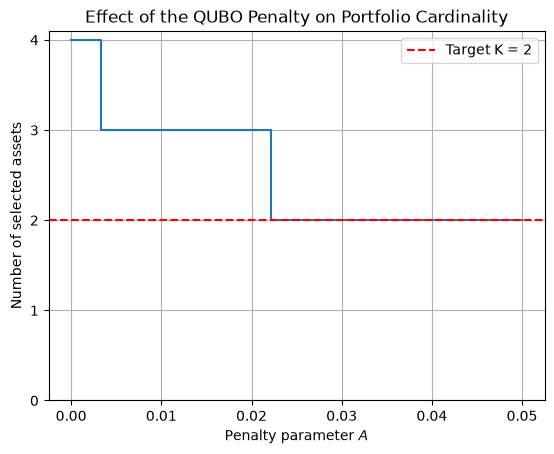

In [11]:
plt.step(penalties, selected_counts, where="post")
plt.axhline(K, color="red", linestyle="--", label=f"Target K = {K}")

plt.xlabel(r"Penalty parameter $A$")
plt.ylabel("Number of selected assets")
plt.title("Effect of the QUBO Penalty on Portfolio Cardinality")
plt.yticks(range(n_assets + 1))
plt.grid(True)
plt.legend()
plt.show()

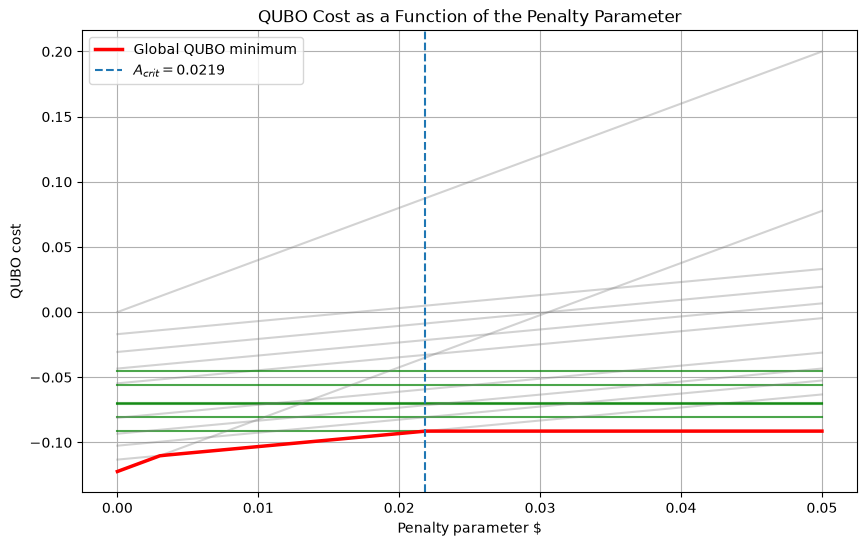

In [12]:
plt.figure(figsize=(10, 6))

for z in all_z:

    # Cost without the cardinality penalty
    base_cost = discrete_portfolio_cost(z, sigma, m, K, gamma)

    # Number of assets selected
    n_selected = np.sum(z)

    # QUBO cost for every value of A
    costs_A = base_cost + penalties * (n_selected - K)**2

    if n_selected == K:
        plt.plot(penalties, costs_A, color="green", alpha=0.7)
    else:
        plt.plot(penalties, costs_A, color="gray", alpha=0.35)

plt.plot(penalties, minimum_costs, color="red", linewidth=2.5, label="Global QUBO minimum")

# I have inserted A crit manually, if any of the values are changed this also need to be changed manually later
plt.axvline(0.0218625, label = '$A_{crit} = 0.0219$', linestyle='--')
plt.xlabel(r"Penalty parameter $")
plt.ylabel(r"QUBO cost")
plt.title("QUBO Cost as a Function of the Penalty Parameter")
plt.grid(True)
plt.legend()
plt.show()

The green lines represent feasbile optimal portfolios. This means that in these the condition K=2 is satisfied and they are therefore horizontal as they don't change (no assets added or subtracted). The grey lines are not allowed, as these do not necessarily have only two assets selected. The red line selects the optimal portfolio and straightens out at around A=0.22. This means that at this size of parameter A, the condition is satisfied. For parameter values below this, the optimum portfolio is no longer comprised of just two assets.

For this system, we can check our result analytically. I have already incorporated this into the graph via the vertical line. We know what our $C(z^{\star})$ is. For each infeasbile portfolio $C_{QUBO}$ needs to be bigger than $C(z^{\star})$. We can rearange this in terms of A and get:

$$ A > \frac{C(z^{\star}) - C(z)}{(e^Tz -K)^2} $$

Then our ciritical A value can be found, where these expressions are equal.

$$ A_{\textrm{crit}}= \max\bigg(0, \max_{e^Tz\neq K}\frac{C(z^{\star}) - C(z)}{(e^Tz -K)^2}\bigg)$$

In [13]:
# calculate the term in the brackets for all terms where k is unequal 2
thresholds = []

for z in all_z:
    if np.sum(z) != K:
        cost = discrete_portfolio_cost(z, sigma, m, K, gamma)

        threshold = (min_cost -cost)/(np.sum(z)-K)**2
        thresholds.append(threshold)

# find the max between the value and 0
A_crit = max(0, max(thresholds))
print('The critical value of A is: ', A_crit)

The critical value of A is:  0.02186250000000002


## 4. Quantum Approximation Optimization Approach

### 4.1 Mapping the QUBO to an Ising Hamiltonian

A Quantum Computer can represent binary variables using qubits. These have Eigenstates $\ket{0}$ and $\ket{1}$. The idea here is that we use the Z and I operator to create an operator with Eigenvalues 0 and 1. This will represent our binary variable. We can construct this by prmoting our binary variable z to an operator.

$$ \hat{z_i} = \frac{I-Z_i}{2} $$

We have already constructed a symmetric QUBO matrix: $ C(z) = \sum_i Q_{ii}z_i +\sum_{i<j} Q_{ij}z_iz_j +  AK^2$. We can insert our expression for z_i and retrieve our Ising Hamiltonian.

$$ H_I = J_{ij}\sum_{i<j}Z_iZ_j + h_i\sum_iZ_i +cI $$

With $J_{ij} = \frac{Q_{ij}}{2}$, $h_i=-\frac{1}{2}\sum_jQ_{ij}$. and $c=\frac{1}{2}\sum_iQ_{ii} + \frac{1}{2}\sum_{i<j}Q_{ij} +AK^2$. This now exactly has the form of an Ising Hamiltonian with an interaction term and an external term (I used the same structure as in my Ising Hamiltonian notebook). The minimizing portoflio is equal to the basis state with the lowest energy. As Ic is just a constant it does not change the Eigenvalue, but just adds a global phase. We don't have to regard it when calculating the circuit, but it is going to be important when calculating absolute energies. So we have to find the lowest energy basis state of:

$$ H_I \ket{z} = C(z)_{QUBO} \ket{z}$$

The Ising energy is $E(z) = J_{ij}\sum_{i<j}s_is_j +h^Ts +c $.

In [14]:
from portfolio_optimization.ising import qubo_to_ising

In [15]:
# initialize our coefficients
h, J, c = qubo_to_ising(Q, offset= A*K**2)

ising_energies = []
qubo_energies =[]

for z in all_z:
    # use the spin relation s = 1-2*z
    s = 1-2*z

    #ising energy
    ising_energy = h @ s +c
    for i in range(n_assets):
        for j in range(i+1, n_assets):
            ising_energy += J[i,j]*s[i]*s[j]

    qubo_energy = z @ Q @ z +A*K**2

    ising_energies.append(ising_energy)
    qubo_energies.append(qubo_energy)

print('All energies agree: ', np.allclose(ising_energies, qubo_energies))

All energies agree:  True


### 4.2 QAOA Implementation

We have already established that the goal is to determine the lowest energy basis state and using the QUBO and classical Markowitz approach we have already determined what that state is. We will now try to reproduce the result using QAOA. The idea is to find the lowest energy via a parametrized circuit and a classical optimizer.

To start we will initialize our four (number of asset) qubits in an equal superposition, by applying Haddamard gates. We then introduce a phase representing the cost of each portfolio, $U_C(\theta) = e^{-i\theta H_c}$. To allow for a movement of amplitudes between different bases, a mixer is introduced. This is represented by the X-Pauli-operator and the unitary transformation is $U_M{\beta} = e^{-i\beta H_M}$, where $H_M$ is just a simple mixing Hamiltonian, $H_M = \sum_i X_i$. The initial basis is $\ket{+}^{\otimes 4}= \frac{1}{\sqrt{16}}\sum{z\in\{0,1\}^4}\ket{z}$, so the state that is prepared can be written as the two transformations acting on this state:

$$\ket{\psi(\theta,\beta)}= U_M(\beta)U_C(\theta)\ket{+}^{\otimes 4}$$

To get the lowest energy state, we use a classical optimizer to minimize:

$$ \bra{\psi(\theta,\beta)}H_C\ket{\psi(\theta,\beta)}

In [16]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from portfolio_optimization.qaoa import qaoa_circuit
from portfolio_optimization.qaoa import qaoa_expected_energy
from portfolio_optimization.qaoa import optimize_qaoa

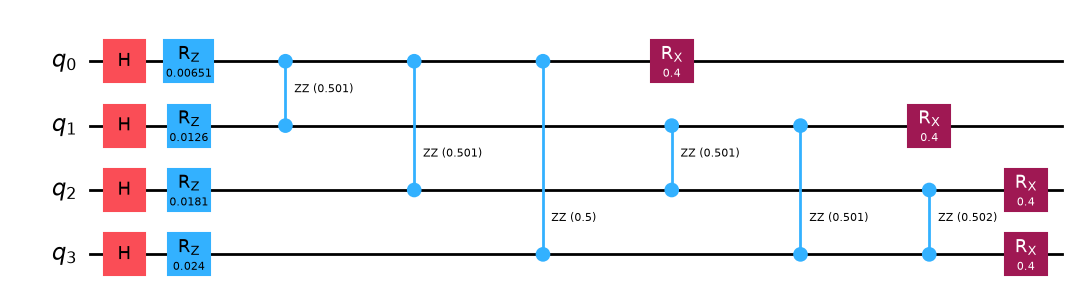

In [17]:
# random angles used for the graphical representation of the circuit
# the function takes in an array to allow for multiple layers in form of (theta1, theta2, beta1, beta2)
theta_beta = [0.5, 0.2]

qc = qaoa_circuit(h, J, theta_beta)

display(qc.draw("mpl"))

From a quantum state $\ket{\psi} = \sum_z a_z\ket{z}$ we know that the probability to measure state z is $P(z) = |a_z|^2$. We want to make the probability to measure the optimal portfolio as large as possible. First let's check the expectation value of the Hamiltonian. We can do this by calculting $E(\theta, \beta) = \sum_z P_z(\theta, \beta)C_{\textrm{QUBO}}(z)$.

In [ ]:
# qiskit and itertools have opposite numbering conventions. We need to reverse z
qiskit_energies = []
for z in all_z:
    z_qiskit = z[::-1]
    cost = discrete_portfolio_cost(z_qiskit, sigma, m, K, gamma)
    penalty = A*(np.sum(z_qiskit)-K)**2

    energy = cost + penalty
    qiskit_energies.append(energy)

# need an array for the qaoa_expected_energy function
qiskit_energies= np.array(qiskit_energies)

expected_energy = qaoa_expected_energy(theta_beta, h, J, qiskit_energies)

print('The expected energy of the system is ', expected_energy)
print("Minimum possible energy:", np.min(qiskit_energies))
print("Maximum possible energy:", np.max(qiskit_energies))

The expected energy of the system is  1.8917220427710615
Minimum possible energy: -0.09135
Maximum possible energy: 4.0


We have verified, that the lowest possible energy is equivalent to the cost of the optimal portfolio. We have also found that for $\theta=0.5$ and $\beta=0.2$, we get a cost that is an order of magnitude larger. We will use scipy.optimize again, but using the COBYLA algorithm to determine:
$$ \theta^{\star},\beta^{\star} = \argmin_{\theta, \beta} \bra{\psi(\theta, \beta)}H_C\ket{\psi(\theta, \beta)} $$
Then we will use these optimal parameters, to look at the probability of measuring the optimal state. Before the probability of each state is $\frac{1}{16}$.

In [ ]:
# scipy numerical optimization
result = optimize_qaoa(h, J, qiskit_energies, theta_beta)

print("Optimization successful:", result.success)
print("Optimal parameters:", result.x)
print("Optimized energy:", result.fun)
print("Ground-state energy:", np.min(qiskit_energies))

Optimization successful: True
Optimal parameters: [2.64298818 1.28909228]
Optimized energy: 0.2370356982981669
Ground-state energy: -0.09135


In [21]:
# construct the optimized state, to get the optimized probability
qc_opt = qaoa_circuit(h, J, result.x)
psi_opt = Statevector.from_instruction(qc_opt)  
probabilities_opt = psi_opt.probabilities()

# find the index of the optimal portfolio, we have z = 0011, but in qiskit its 1100. We also have to join the strings as integers
z_star = np.array([0, 0, 1, 1])
index_star = int("".join(map(str, z_star[::-1])), 2)

# optimized probability
prob_opt = probabilities_opt[index_star]

print("The probability of measuring the optimal state after optimization is ", prob_opt)

The probability of measuring the optimal state after optimization is  0.12662348497270975


The probability of measuring the optimal state is about 1.79 times larger than it was before. However, 13% is not a ver succesful result. There can be many reasons for this. Firstly, we are only using one layer of QAOA. This restricts the expressivness of the circuit. Here we have also used A=1 even though we found the critical penalty parameter to be much lower. We will investigate if this has an effect. It could als be that COBYLA converged to a local minimum, rather than a global one, and that this fulfilled its convergence requirment. Before we investigate any of this, we will check whether there is a difficulty in choosing feasbile portfolio, i.e. how high the probability of a feasible portfolio is.

In [ ]:
# find the probability of a feasible portfolio being selected
p_feasible = 0

for index, z in enumerate(all_z):
    if np.sum(z) == K:
        p_feasible += probabilities_opt[index]

print("Probability of feasible portfolio:", p_feasible)

Probability of feasible portfolio: 0.7352669988055869


This is a large increase from $\frac{6}{16}$. So QAOA is likely to pick a feasible portfolio, but has trouble picking the optimal one. We can find the conditional probability of $z^{\star}$ being selected if a feasbile portfolio is selected: P($z^{\star}$|feasbile) = $\frac{\textrm{P}(z^{\star})}{\textrm{P}_{\textrm{feasbile}}}$ = 16%. This is the standard $\frac{1}{6}$ probability. So the optimization only increases the probability of measuring a feasible portfolio, not necessarily the optimal one.

### 4.3 Penalty Parameter Comparison

I will keep this section brief. We will test a five discrete penalty parameters at different magnitudes and see if this has an effect on the probabilities we calculated in the previous section.

In [23]:
import pandas as pd

In [ ]:
# values of A we are testing
penalty_values = [0.01, 0.025, 0.1, 0.5, 1.0, 2.0]

results = []

for penalty in penalty_values:

    # Construct QUBO and Ising Hamiltonian
    Q = QUBO_matrix(sigma, m, K, gamma, penalty)
    h, J, c = qubo_to_ising(Q, offset=penalty * K**2)

    # Calculate all QUBO energies in Qiskit's ordering
    energies = []

    for z in all_z:
        z_qiskit = z[::-1]
        energy = (
            discrete_portfolio_cost(z_qiskit, sigma, m, K, gamma)
            + penalty * (np.sum(z_qiskit) - K)**2
        )
        energies.append(energy)

    energies = np.array(energies)

    # Optimize QAOA
    result = optimize_qaoa(h, J, energies, theta_beta)

    # Calculate optimized state probabilities
    qc = qaoa_circuit(h, J, result.x)
    probabilities = Statevector.from_instruction(qc).probabilities()

    # Optimal portfolio probability (Qiskit index 12)
    p_optimal = probabilities[12]

    # Probability of obtaining exactly K assets
    p_feasible = sum(
        probabilities[index]
        for index, z in enumerate(all_z)
        if np.sum(z) == K
    )

    results.append([penalty, result.fun, p_optimal, p_feasible, result.success])

In [27]:
df = pd.DataFrame( results,
    columns=["Penalty A", "Expected Energy", "P(optimal)","P(feasible)", "Converged"]   )

display(df)

,Penalty A,Expected Energy,P(optimal),P(feasible),Converged
0,0.010,-0.085663,0.069697,0.179463,False
1,0.025,-0.045718,0.073113,0.501457,False
2,0.100,-0.032589,0.112413,0.717382,False
3,0.500,0.084067,0.121509,0.738182,True
4,1.000,0.237036,0.126623,0.735267,True
5,2.000,0.538097,0.125081,0.738142,True


From the table we can see that the penalty parameter does what it should do. After about 0.5 we get diminishing results and further increasing A does not increase any of the probabiltities significantly.

### 4.4 Circuit Depth

The last thing we will look at is how circuit depth affects the probabilities. For a given depth the state is then:

$$\ket{\psi(\theta, \beta)} = \prod_{l=p}^{1} e^{-i\beta_M H_M}e^{-i\theta_l H_c} $$

In [ ]:
# pick arbitrary inital parameters for depth 1, 2, and 3, initialized as a dictionary
initial_parameters = {
    1: [0.5, 0.2],
    2: [0.5, 0.8, 0.2, 0.4],
    3: [0.5, 0.8, 1.0, 0.2, 0.4, 0.6]
}

depth_results = []

# loop over the three depths, items returns pairs from the dictionary
# p goes from 1-3 and initial are the guessed angles
for p, initial in initial_parameters.items():
    # optimize angles
    result = optimize_qaoa(h, J, qiskit_energies, initial)

    qc = qaoa_circuit(h, J, result.x)

    probabilities = Statevector.from_instruction(qc).probabilities()

    # our optimal solution had index integer 12
    p_optimal = probabilities[12]

    # probability of getting a protfolio that has K=sum(z)
    p_feasible = sum(
        probabilities[index]
        for index, z in enumerate(all_z)
        if np.sum(z) == K
    )

    # store all relevant values
    # nfev is the number of objective evaluation
    depth_results.append([
        p,
        result.fun,
        p_optimal,
        p_feasible,
        result.success,
        result.nfev
    ])

In [37]:
df_depth = pd.DataFrame( depth_results,
    columns=["Depth p", "Expected Energy", "P(optimal)", "P(feasible)", "Converged", "Evaluations"]  )

display(df_depth)

,Depth p,Expected Energy,P(optimal),P(feasible),Converged,Evaluations
0,1,0.234361,0.125062,0.738016,True,68
1,2,-0.066479,0.169416,0.998726,True,406
2,3,-0.053493,0.171321,0.984988,False,3000


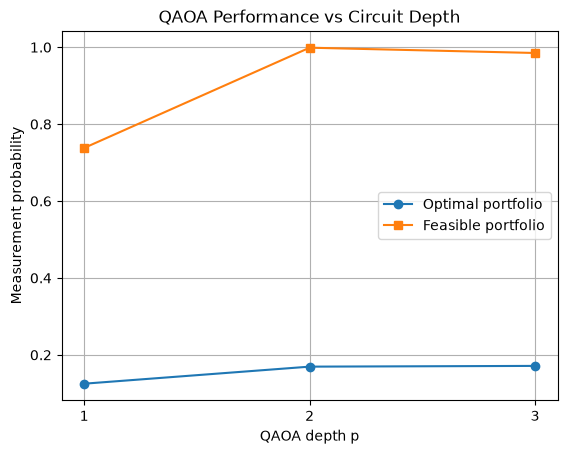

In [38]:
plt.plot(
    df_depth["Depth p"],
    df_depth["P(optimal)"],
    "o-",
    label="Optimal portfolio"
)

plt.plot(
    df_depth["Depth p"],
    df_depth["P(feasible)"],
    "s-",
    label="Feasible portfolio"
)

plt.xlabel("QAOA depth p")
plt.ylabel("Measurement probability")
plt.xticks([1, 2, 3])
plt.title("QAOA Performance vs Circuit Depth")
plt.legend()
plt.grid(True)
plt.show()

Increasing depth significantly impacts the probability of measuring a feasible portfolio, but only slightly increases the chances of the optimal portfolio being measured. This suggests that it becomes good ad distinguishing the constraint, but cannot find the optimal portfolio. At depth 3, the optimizer did not manage to converge after the maximum of 3000 evaluations was reached. We can also run into the problem of finding local instead of global minima, but this shows that a higher probability of finding a feasbile portfolio does not translate into the measurement of an optimal portfolio.

## 5. Conclusion

In this notebook, we extended the classical Markowitz portfolio optimization problem to a discrete optimization problem and investigated how it can be solved using QAOA.

We first introduced binary variables to represent whether an asset is included in the portfolio. By adding a penalty term for violating the cardinality constraint, we reformulated the problem as a QUBO and subsequently mapped it to an Ising Hamiltonian. We verified that the different formulations give the same energies and used an exhaustive classical search to find the exact optimal portfolio, which serves as a benchmark for QAOA.

We then implemented QAOA and investigated how the penalty parameter and the number of circuit layers affect the results.

Increasing the penalty parameter generally improved the probability of obtaining a feasible portfolio. However, beyond a certain value, further increasing the penalty did not significantly improve the results.

We also found that increasing the number of QAOA layers from \(p=1\) to \(p=2\) significantly improved the performance. The expected energy decreased from approximately \(0.2344\) to \(-0.0665\), approaching the exact minimum of \(-0.09135\). More importantly, the probability of obtaining a feasible portfolio increased from \(73.8\%\) to \(99.9\%\).

However, the probability of obtaining the actual optimal portfolio only increased from \(12.5\%\) to \(16.9\%\). Since there are six feasible portfolios, this is only slightly better than randomly choosing one of them. This suggests that QAOA was much more successful at satisfying the cardinality constraint than at identifying the best portfolio among the feasible ones.

For \(p=3\), the optimizer did not converge within the specified number of evaluations, so we cannot draw a clear conclusion about whether adding another layer improves the results.

Overall, this was a useful way to understand how a classical optimization problem can be translated into a quantum algorithm. It also showed some of the limitations of QAOA. A lower expected energy does not necessarily mean that the probability of measuring the optimal solution is significantly higher, and increasing the circuit depth also makes the classical optimization of the parameters more difficult.

Since we only considered four assets and used an exact statevector simulation, we cannot make any claims about quantum advantage. For such a small problem, classical exhaustive search is clearly the more practical approach. Nevertheless, this provides a starting point for understanding how QUBO problems can be encoded into quantum circuits and how the performance of variational quantum algorithms can be evaluated.